In [1]:
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import (
    LinearRegression, SGDRegressor, HuberRegressor, TheilSenRegressor, RANSACRegressor, QuantileRegressor
)
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR, LinearSVR, NuSVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels.csv', index_col='ID')
categorical_features=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_categorical_features.csv', index_col='ID')
numerical_features=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_numercial_features.csv', index_col='ID')

## 🛑 Task 2.1: AGE

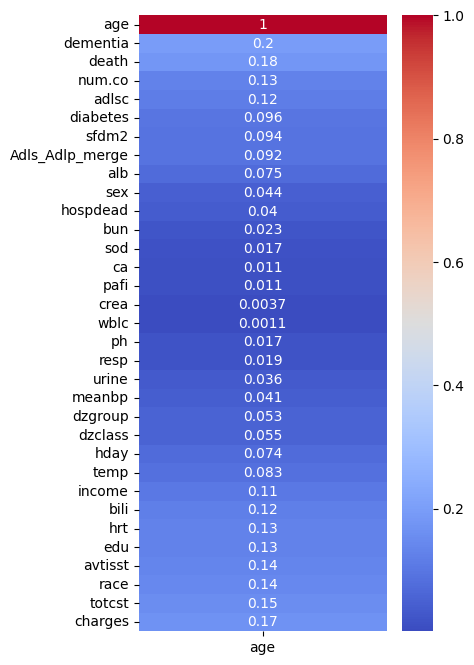

In [2]:
plt.figure(figsize=(4, 8))
sns.heatmap(df.corr()["age"].sort_values(ascending=False).abs().to_frame(), annot=True, cmap='coolwarm')
plt.show()

The variables are not highly linearly correlated

### 🛑  Model Analysis

In [3]:
target=df['age']
features=df.drop(['age'],axis=1)
categorical_features_cols= categorical_features.columns
numerical_features_cols = numerical_features.columns.drop('age').tolist()



In [4]:
# Definir StratifiedKFold (estratificando la variable objetivo discretizada)
bins = pd.qcut(target, q=5, labels=False)  # Discretizar en quintiles
kfold_external = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
data_dict = {}
# Crear un DataFrame para guardar resultados
evaluation_metrics_scaled = pd.DataFrame(columns=['Model', 'MAE_VAL', 'MAPE_VAL', 'RMSE_VAL', 'R2_VAL', 'R2_adjusted_VAL', 'MAE_TRAIN', 'MAPE_TRAIN', 'RMSE_TRAIN', 'R2_TRAIN', 'R2_adjusted_TRAIN'])

# Función para calcular métricas
def evaluate_model(y_true, y_pred, n, p):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    r2 = r2_score(y_true, y_pred)
    r2_adjusted = 1 - ((1 - r2) * (n - 1) / (n - p - 1))
    return mae, mape, rmse, r2, r2_adjusted

# Modelos de regresión
models = {
    "Linear Regression": LinearRegression(),
    "Quantile Regression": QuantileRegressor(quantile=0.5),
    "Polynomial Regression (Degree=2)": Pipeline([
        ("poly_features", PolynomialFeatures(degree=2)),
        ("linear_regression", LinearRegression())
    ]),
    "Linear SVR": LinearSVR(random_state=42),
    "SVR": SVR(),
    "NuSVR": NuSVR(),
    "SGD Regression": SGDRegressor(random_state=42),
    "Nearest Neighbor Regression": KNeighborsRegressor(),
    "Decision Tree Regression": DecisionTreeRegressor(random_state=42),
    "RANSAC Regression": RANSACRegressor(random_state=42),
    "Theil-Sen Regression": TheilSenRegressor(random_state=42),
    "Huber Regressor": HuberRegressor()
}

for fold, (train_val_index, test_index) in enumerate(kfold_external.split(features, bins)):
    fold_external_dict = {}
    # Dividir en conjunto de prueba y conjunto de entrenamiento/validación
    X_train_val, X_test = features.iloc[train_val_index], features.iloc[test_index]
    y_train_val, y_test = target.iloc[train_val_index], target.iloc[test_index]
    
    # Índices alineados 
    bins_train_val = bins.iloc[train_val_index]
    
    # Inicialización de KFold interno
    kfold_internal = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)
    number=1
    for train_index, val_index in kfold_internal.split(X_train_val, bins_train_val):
        # División en conjuntos de entrenamiento y validación
        X_train = X_train_val.iloc[train_index]
        y_train = y_train_val.iloc[train_index]
        X_val = X_train_val.iloc[val_index]
        y_val = y_train_val.iloc[val_index]

        # Separar variables cuantitativas y cualitativas
        X_train_quantitative = X_train[numerical_features_cols]
        X_val_quantitative = X_val[numerical_features_cols]
        X_test_quantitative = X_test[numerical_features_cols]
        X_train_qualitative = pd.get_dummies(X_train[categorical_features_cols], drop_first=True)
        X_val_qualitative = pd.get_dummies(X_val[categorical_features_cols], drop_first=True)
        X_test_qualitative = pd.get_dummies(X_test[categorical_features_cols], drop_first=True)
        
        # Normalizar datos
        # Initialize the scaler
        scaler = StandardScaler()

        # Fit and transform on the training data, preserving the index
        X_scaled_train = scaler.fit_transform(X_train_quantitative)
        X_scaled_train = pd.DataFrame(X_scaled_train, columns=X_train_quantitative.columns, index=X_train_quantitative.index)

        # Transform validation data (using the same scaler fitted on training data), preserving the index
        X_scaled_val = scaler.transform(X_val_quantitative)
        X_scaled_val = pd.DataFrame(X_scaled_val, columns=X_val_quantitative.columns, index=X_val_quantitative.index)

        # Transform test data (using the same scaler fitted on training data), preserving the index
        X_scaled_test = scaler.transform(X_test_quantitative)
        X_scaled_test = pd.DataFrame(X_scaled_test, columns=X_test_quantitative.columns, index=X_test_quantitative.index)

        X_scaled_train=pd.concat([X_scaled_train,X_train_qualitative],axis=1)
        X_scaled_val=pd.concat([X_scaled_val,X_val_qualitative],axis=1)
        X_scaled_test=pd.concat([X_scaled_test,X_test_qualitative],axis=1)

        # Guardar los datos procesados
        fold_internal_key = f'Fold_Interno_{number}'
        fold_external_dict[fold_internal_key] = {
            'Train_X': X_scaled_train,
            'Train_Y': y_train,
            'Validation_X': X_scaled_val,
            'Validation_Y': y_val,
            'Test_X': X_scaled_test,
            'Test_Y': y_test
        }

        # Guardar el fold externo con todos los internos
        fold_external_key = f'Fold_Externo_{fold}'
        data_dict[fold_external_key] = fold_external_dict

        for model_name, model in models.items():
            # Ajustar el modelo y realizar predicciones
            model.fit(X_scaled_train, y_train)
            y_pred = model.predict(X_scaled_val)

            # Calcular las métricas para el set de validación
            n, p = X_scaled_test.shape
            mae, mape, rmse, r2, r2_adjusted = evaluate_model(y_val, y_pred, n, p)

           

            # Calculando las métricas para el conjunto de train
            mae_train, mape_train, rmse_train, r2_train, r2_adjusted_train = evaluate_model(y_train, model.predict(X_scaled_train), n, p)

            # Registrar las métricas
            model_row = pd.DataFrame([{
                'Model': model_name,
                'MAE_VAL': mae,
                'MAPE_VAL': mape,
                'RMSE_VAL': rmse,
                'R2_VAL': r2,
                'R2_adjusted_VAL': r2_adjusted,
                'MAE_TRAIN': mae_train,
                'MAPE_TRAIN': mape_train,
                'RMSE_TRAIN': rmse_train,
                'R2_TRAIN': r2_train,
                'R2_adjusted_TRAIN': r2_adjusted_train

            }])
            evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)
        number=number+1

# Mostrar resultados finales
evaluation_metrics_scaled.head()

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_76371/1028027018.py:127: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)


,Model,MAE_VAL,MAPE_VAL,RMSE_VAL,R2_VAL,R2_adjusted_VAL,MAE_TRAIN,MAPE_TRAIN,RMSE_TRAIN,R2_TRAIN,R2_adjusted_TRAIN
0,Linear Regression,11.317729,22.457802,14.152666,0.183124,0.168006,11.206682,22.182225,14.071424,0.184997,0.169913
1,Quantile Regression,12.449843,25.896912,15.812394,-0.019705,-0.038578,12.403402,25.720365,15.739276,-0.019653,-0.038525
2,Polynomial Regression (Degree=2),11.516852,22.296287,14.728268,0.115327,0.098954,9.512601,18.443299,12.105073,0.396861,0.385698
3,Linear SVR,11.354265,23.028480,14.366267,0.158281,0.142702,11.220622,22.723881,14.284202,0.160163,0.144620
4,SVR,11.377149,23.570897,14.477038,0.145251,0.129431,11.083679,22.985597,14.252019,0.163943,0.148470


In [5]:
evaluation_metrics_scaled.groupby('Model').mean().sort_values('R2_adjusted_VAL', ascending=False)

,MAE_VAL,MAPE_VAL,RMSE_VAL,R2_VAL,R2_adjusted_VAL,MAE_TRAIN,MAPE_TRAIN,RMSE_TRAIN,R2_TRAIN,R2_adjusted_TRAIN
Model,,,,,,,,,,
Linear Regression,11.281548,22.250846,14.124438,0.180066,0.164889,11.186365,22.066012,14.002602,0.194143,0.179227
Huber Regressor,11.224294,22.604962,14.191345,0.172263,0.156942,11.105160,22.392653,14.068112,0.186590,0.171534
SGD Regression,11.358802,22.373732,14.217616,0.169219,0.153841,11.261814,22.183821,14.087569,0.184324,0.169226
Theil-Sen Regression,11.375931,22.443677,14.282020,0.161661,0.146143,11.284461,22.272750,14.180270,0.173573,0.158276
NuSVR,11.413959,22.969555,14.310030,0.158393,0.142815,11.235783,22.630816,14.087969,0.184299,0.169201
Linear SVR,11.331581,22.904943,14.356159,0.152916,0.137237,11.170626,22.630023,14.230663,0.167687,0.152281
SVR,11.332456,23.287034,14.390660,0.148858,0.133103,11.005662,22.706803,14.124465,0.180072,0.164895
Polynomial Regression (Degree=2),11.530620,22.238514,14.878154,0.089368,0.072513,9.533548,18.358650,12.041399,0.404035,0.393004
Nearest Neighbor Regression,11.989607,23.432446,15.179773,0.052918,0.035388,9.728846,18.922154,12.317273,0.376449,0.364907


--- 
# ⭐️ GENERAL CONCLUSIONS BETTER MODEL DUE TO THEIR PERFORMANCE

# Regression Models Analysis

## 1. Best Performing Models
The best models are **Linear Regression** and **Huber Regressor**, with the lowest error values (MAE, MAPE, and RMSE) and the highest \( R^2 \) values for both validation and training:

- **Linear Regression**: 
  - MAE_VAL = 11.28 
  - R2_VAL = 0.18 
- **Huber Regressor**:
  - MAE\_VAL = 11.22 
  - R2_VAL = 0.17 

Although the differences are small, **Linear Regression** achieves a balance between performance in training and validation.

---

## 2. Similar Performing Models
Models such as **SGD Regression**, **Theil-Sen Regression**, and **SVR** show very similar performance in validation, with slightly higher errors than the best models, but maintain positive \( R^2 \) values (ranging from 0.14 to 0.17).

---

## 3. Worst Performing Models
**Decision Tree Regression** and **RANSAC Regression** clearly perform the worst:

- **Decision Tree Regression**: 
  - R2_VAL = -0.54
  - High errors in validation.
- **RANSAC Regression**:
  - R2_VAL = -2.80 
  - The highest error in validation MAE = 22.13, RMSE = 30.03.

These models show clear overfitting or a lack of generalization ability.

---

## 4. Polynomial and Nearest Neighbor Models
- **Polynomial Regression (Degree=2)** and **Nearest Neighbor Regression** show lower predictive capacity:
  - R2_VAL = 0.08 (Polynomial)
  - R2_VAL = 0.05 (Nearest Neighbor).

The complexity of these models does not provide significant improvement in this case.

---

## 5. Model Generalization
- The **Polynomial Regression** model performs much better in training R2_TRAIN = 0.40 compared to validation R2_VAL = 0.08, indicating **overfitting**.
- Models like **NuSVR** and **Linear SVR** maintain a balance in errors between validation and training but do not outperform the best models.

---

## 6. Limitations and Next Steps
Given the **limited time** and overall poor performance of all models, we have not done any further tuning or exploration of these models at this stage. However, these results could be **significantly improved** with:
- More appropriate training (more data or better preprocessing).
- Better adjustment and optimization of parameters.
- Advanced techniques such as **hyperparameter optimization** (e.g. GridSearch, Bayesian optimization).

To satisfy the requirements of this task, we have focused on T2.3_CHARGES.
